# Category-Conditioned Sketch Generation with Variational Autoencoders

**Author:** Ashwin Parthasarathy

This project develops a sketch generator in PyTorch using human-drawn examples from Google Quick, Draw!. Development begins with a one-category feasibility experiment before expanding to category-conditioned generation.

Evaluation will examine randomly generated samples, recognizability, diversity, and similarity to training examples. Model choices and quality claims will be grounded in the experiments recorded in this notebook.

## 1. Environment and reproducibility

In [1]:
import hashlib
import json
import random
import shutil
import sys
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

In [2]:
PROJECT_ROOT = Path.cwd()
SEED = 42

In [3]:
assert (PROJECT_ROOT / ".git").is_dir(), (
    "Open this notebook from the sketch-generation-vae repository root."
)

# Seed the random generators used for data selection and model training.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Project:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("Device:", device)

Project: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae
Python: 3.14.0
Executable: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae/.venv/bin/python
PyTorch: 2.15.0
Device: mps


## 2. Dataset acquisition and initial inspection

The project uses human-drawn sketches from [Google Quick, Draw!](https://github.com/googlecreativelab/quickdraw-dataset), released under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

The initial feasibility experiment uses the apple category. The supplied NumPy file contains flattened 28 × 28 grayscale images rendered from simplified human drawings. Rasterization is preprocessing; these are not AI-generated training examples.

The bitmap file does not retain contributor identifiers, country information, or recognition flags. Consequently, it does not support contributor-independent splitting or demographic analysis.

This section inspects the downloaded data. Training, validation, and test partitions will be created separately before model development.

In [4]:
DATA_URL = (
    "https://storage.googleapis.com/"
    "quickdraw_dataset/full/numpy_bitmap/apple.npy"
)
DATA_PATH = PROJECT_ROOT / "data/raw/apple.npy"
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    temporary_path = DATA_PATH.with_suffix(".npy.partial")
    print("Downloading apple sketches...", flush=True)

    # Publish the file only after the download finishes.
    with urlopen(DATA_URL, timeout=60) as response:
        expected_bytes = response.headers.get("Content-Length")
        with temporary_path.open("wb") as destination:
            shutil.copyfileobj(response, destination)

    if expected_bytes is not None:
        assert temporary_path.stat().st_size == int(expected_bytes), (
            "Download size mismatch; do not use this file."
        )

    temporary_path.replace(DATA_PATH)

In [5]:
# Memory mapping avoids loading the entire category into RAM.
apple_images = np.load(DATA_PATH, mmap_mode="r", allow_pickle=False)

assert apple_images.ndim == 2 and apple_images.shape[1] == 28 * 28
assert apple_images.dtype == np.uint8
assert len(apple_images) >= 30000

In [6]:
file_hash = hashlib.sha256()
with DATA_PATH.open("rb") as handle:
    for chunk in iter(lambda: handle.read(1024 * 1024), b""):
        file_hash.update(chunk)

source_record = {
    "dataset": "Google Quick, Draw!",
    "category": "apple",
    "url": DATA_URL,
    "license": "CC BY 4.0",
    "verified_at_utc": datetime.now(timezone.utc).isoformat(),
    "sha256": file_hash.hexdigest(),
    "bytes": DATA_PATH.stat().st_size,
    "shape": list(apple_images.shape),
    "dtype": str(apple_images.dtype)
}

(PROJECT_ROOT / "reports").mkdir(exist_ok=True)
with (PROJECT_ROOT / "reports/apple_source.json").open("w") as handle:
    json.dump(source_record, handle, indent=2)

print("Images:", len(apple_images))
print("Image dimensions: 28 × 28")
print("Data type:", apple_images.dtype)
print(f"File size: {DATA_PATH.stat().st_size / 1024**2:.1f} MiB")
print("SHA-256:", source_record["sha256"])

Images: 144722
Image dimensions: 28 × 28
Data type: uint8
File size: 108.2 MiB
SHA-256: a70df0030c146cfe4aa9a17aa2a320d5f64ac166fdc3d2cfb439b8322fd8bb0d


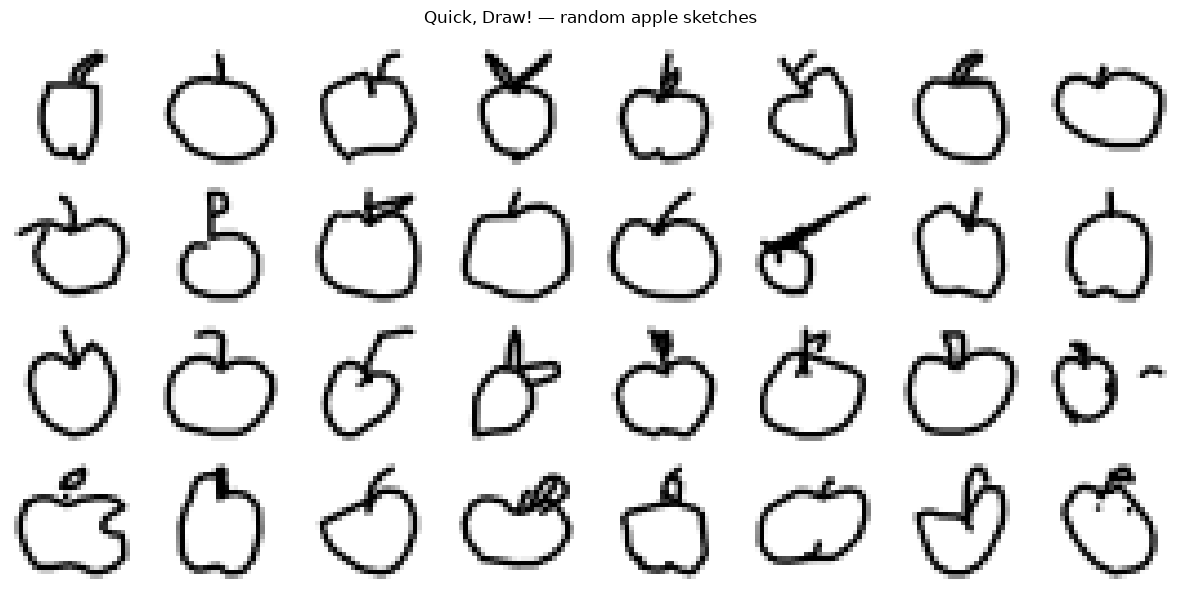

In [7]:
preview_rng = np.random.default_rng(SEED)
preview_indices = preview_rng.choice(len(apple_images), size=32, replace=False)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))

for axis, index in zip(axes.flat, preview_indices):
    axis.imshow(
        apple_images[index].reshape(28, 28),
        cmap="gray_r",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )
    axis.axis("off")

fig.suptitle("Quick, Draw! — random apple sketches")
fig.tight_layout()
plt.savefig("figures/random_apple_sketches.png")
plt.show()
plt.close(fig)

## 3. Automated audit and reproducible data splits

Blank images and exact pixel duplicates are excluded automatically. Duplicate detection uses SHA-256 hashes of the original 28 × 28 pixel arrays; it does not detect near duplicates or identify individual contributors.

A seeded random sample of 30,000 unique, nonblank sketches forms the feasibility dataset: 24,000 training, 3,000 validation, and 3,000 test images.

The manifest records each image's row index in the downloaded NumPy file and its pixel hash. Combined with the source file's SHA-256 checksum, this allows the same selection to be reconstructed without committing the raw images.

Validation guides model development. Test images remain unused until the final evaluation. No subjective filtering is applied to drawing quality.

In [8]:
# Audit all images before selecting the experiment subset.
unique_rows = []
seen_hashes = set()
blank_count = 0
duplicate_count = 0

for source_index in range(len(apple_images)):
    pixels = apple_images[source_index]

    # Quick, Draw! bitmaps use zero for background and larger values for ink.
    if not np.any(pixels):
        blank_count += 1
        continue

    pixel_hash = hashlib.sha256(pixels.tobytes()).hexdigest()

    if pixel_hash in seen_hashes:
        duplicate_count += 1
        continue

    seen_hashes.add(pixel_hash)
    unique_rows.append({
        "source_index": source_index,
        "category": "apple",
        "pixel_sha256": pixel_hash,
    })

unique_inventory = pd.DataFrame(unique_rows)
assert len(unique_inventory) >= 30000

# Shuffle once, reproducibly, then assign nonoverlapping partitions.
split_rng = np.random.default_rng(SEED)
selected_positions = split_rng.choice(len(unique_inventory), size=30000, replace=False)

apple_manifest = unique_inventory.iloc[selected_positions].reset_index(drop=True)

apple_manifest["split"] = (
    ["train"] * 24_000
    + ["validation"] * 3000
    + ["test"] * 3000
)

assert apple_manifest["source_index"].is_unique
assert apple_manifest["pixel_sha256"].is_unique

processed_dir = PROJECT_ROOT / "data/processed"
processed_dir.mkdir(parents=True, exist_ok=True)
apple_manifest.to_csv(processed_dir / "apple_split_manifest.csv", index=False)

audit_record = {
    "source_file_sha256": source_record["sha256"],
    "source_images": len(apple_images),
    "blank_images_excluded": blank_count,
    "duplicate_images_excluded": duplicate_count,
    "unique_nonblank_images": len(unique_inventory),
    "selected_images": len(apple_manifest),
    "seed": SEED,
    "split_counts": {
        split: int(count)
        for split, count in apple_manifest["split"].value_counts().items()
    }
}

with (PROJECT_ROOT / "reports/apple_data_audit.json").open("w") as handle:
    json.dump(audit_record, handle, indent=2)

print("Blank images excluded:", blank_count)
print("Exact duplicate images excluded:", duplicate_count)
print("Unique nonblank images:", len(unique_inventory))
print("\nSelected split counts:")
print(apple_manifest["split"].value_counts())

# Release the temporary audit structures; keep the selected manifest.
del seen_hashes, unique_rows

Blank images excluded: 0
Exact duplicate images excluded: 1
Unique nonblank images: 144721

Selected split counts:
split
train         24000
validation     3000
test           3000
Name: count, dtype: int64


## 4. Image preprocessing and data loading

The feasibility model uses the original 28 × 28 grayscale bitmaps. Pixel intensities are divided by 255, producing floating-point tensors in [0, 1]. Zero represents background and one represents maximum stroke intensity.

No augmentation is applied in the initial experiment. This establishes a baseline before introducing additional preprocessing choices.

Training examples are shuffled using a seeded random generator. Validation examples retain a fixed order. Test data is reserved for final evaluation, and no test loader is created at this stage.

Each tensor has shape (1, 28, 28), where the first dimension is the grayscale channel. Data loading uses num_workers=0 for straightforward execution in Jupyter on the local Mac.

In [9]:
from torch.utils.data import DataLoader, Dataset

In [10]:
BATCH_SIZE = 128

class SketchDataset(Dataset):
    """Read selected sketches from the downloaded bitmap array.

    Parameters
    ----------
    images : numpy.ndarray
        Original uint8 bitmap array shaped (number_of_images, 784).
    manifest : pandas.DataFrame
        Rows containing source_index for the desired split.
    """

    def __init__(self, images, manifest):
        self.images = images
        self.source_indices = manifest["source_index"].to_numpy(
            dtype=np.int64, copy=True
        )

    def __len__(self):
        """Return the number of selected sketches."""
        return len(self.source_indices)

    def __getitem__(self, index):
        """Return one normalized grayscale sketch.

        Parameters
        ----------
        index : int
            Position within this dataset's selected rows.

        Returns
        -------
        torch.Tensor
            Float32 image shaped (1, 28, 28), with values in [0, 1].
        """
        source_index = self.source_indices[index]

        # Copy the read-only memory-mapped row into writable float32 memory.
        pixels = np.array(self.images[source_index], dtype=np.float32, copy=True).reshape(1, 28, 28)
        pixels /= 255.0

        return torch.from_numpy(pixels)


train_dataset = SketchDataset(apple_images, apple_manifest.loc[apple_manifest["split"].eq("train")])
validation_dataset = SketchDataset(apple_images, apple_manifest.loc[apple_manifest["split"].eq("validation")])

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Check dataset entries directly without advancing the training shuffle.
example_batch = torch.stack([train_dataset[index] for index in range(8)])

assert example_batch.shape == (8, 1, 28, 28)
assert example_batch.dtype == torch.float32
assert torch.isfinite(example_batch).all()
assert example_batch.min() >= 0 and example_batch.max() <= 1

print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Training batches per epoch:", len(train_loader))
print("Example batch shape:", tuple(example_batch.shape))
print(
    "Pixel range:",
    f"[{example_batch.min().item():.3f}, "
    f"{example_batch.max().item():.3f}]"
)

Training images: 24000
Validation images: 3000
Training batches per epoch: 188
Example batch shape: (8, 1, 28, 28)
Pixel range: [0.000, 1.000]


## 5. Variational autoencoder architecture

The encoder reduces each 28 × 28 sketch to a feature representation, then predicts the mean and log variance of a 16-dimensional diagonal Gaussian distribution.

During training, the reparameterization step samples a latent vector:

z = mean + standard deviation × random noise

This allows reconstruction gradients to reach the encoder while retaining stochastic sampling. The decoder maps the latent vector back to a 28 × 28 image. It returns logits; applying sigmoid converts these into pixel values in [0, 1].

The decoder uses nearest-neighbor upsampling followed by convolution. Its dimensions progress from 7 × 7 to 14 × 14 and then 28 × 28.

The model supports two distinct evaluations:

- Reconstruction: encode a real sketch and decode its latent representation.
- Generation: sample a latent vector from the standard normal prior and decode it without supplying an input sketch.

Good reconstruction alone does not establish good generation. Both will be inspected separately.

This implementation follows the VAE framework introduced by [Kingma and Welling (2014)](https://arxiv.org/abs/1312.6114).

In [11]:
from torch import nn

LATENT_DIM = 16

class SketchVAE(nn.Module):
    """Encode and generate 28 × 28 grayscale sketches.

    Parameters
    ----------
    latent_dim : int, default=16
        Number of latent dimensions.
    """

    def __init__(self, latent_dim=16):
        super().__init__()
        self.latent_dim = latent_dim

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU()
        )
        self.mean_head = nn.Linear(128, latent_dim)
        self.log_variance_head = nn.Linear(128, latent_dim)

        self.decoder_input = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64 * 7 * 7),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (64, 7, 7)),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(32, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 1, kernel_size=3, padding=1)
        )

    def encode(self, images):
        """Predict the approximate posterior distribution.

        Parameters
        ----------
        images : torch.Tensor
            Sketches shaped (batch, 1, 28, 28).

        Returns
        -------
        tuple[torch.Tensor, torch.Tensor]
            Mean and log variance, each shaped (batch, latent_dim).
        """
        features = self.encoder(images)
        return self.mean_head(features), self.log_variance_head(features)

    def reparameterize(self, mean, log_variance):
        """Sample latent vectors while preserving the gradient path.

        Parameters
        ----------
        mean : torch.Tensor
            Posterior means shaped (batch, latent_dim).
        log_variance : torch.Tensor
            Posterior log variances with the same shape as mean.

        Returns
        -------
        torch.Tensor
            Sampled latent vectors shaped (batch, latent_dim).
        """
        standard_deviation = torch.exp(0.5 * log_variance)
        noise = torch.randn_like(standard_deviation)
        return mean + standard_deviation * noise

    def decode(self, latent):
        """Decode latent vectors into pixel logits.

        Parameters
        ----------
        latent : torch.Tensor
            Latent vectors shaped (batch, latent_dim).

        Returns
        -------
        torch.Tensor
            Pixel logits shaped (batch, 1, 28, 28).
        """
        return self.decoder(self.decoder_input(latent))

    def forward(self, images, sample=True):
        """Reconstruct images through the latent distribution.

        Parameters
        ----------
        images : torch.Tensor
            Normalized sketches shaped (batch, 1, 28, 28).
        sample : bool, default=True
            Sample the posterior if True; otherwise decode its mean.

        Returns
        -------
        tuple[torch.Tensor, torch.Tensor, torch.Tensor]
            Reconstruction logits, posterior means, and log variances.
        """
        mean, log_variance = self.encode(images)
        latent = (
            self.reparameterize(mean, log_variance)
            if sample else mean
        )
        return self.decode(latent), mean, log_variance


# Reset initialization so earlier notebook inspections do not change it.
torch.manual_seed(SEED)
vae = SketchVAE(latent_dim=LATENT_DIM).to(device)

# This shape check performs no optimization or posterior sampling.
vae.eval()
with torch.no_grad():
    logits, mean, log_variance = vae(
        example_batch.to(device), sample=False
    )

assert logits.shape == (8, 1, 28, 28)
assert mean.shape == log_variance.shape == (8, LATENT_DIM)
for tensor in (logits, mean, log_variance):
    assert torch.isfinite(tensor).all().item()

print("Parameters:", f"{sum(p.numel() for p in vae.parameters()):,}")
print("Reconstruction logits:", tuple(logits.shape))
print("Posterior mean:", tuple(mean.shape))
print("Posterior log variance:", tuple(log_variance.shape))

Parameters: 854,433
Reconstruction logits: (8, 1, 28, 28)
Posterior mean: (8, 16)
Posterior log variance: (8, 16)


## 6. Reconstruction loss and latent regularization

The VAE balances two objectives:

1. **Reconstruction:** binary cross-entropy compares the decoder's pixel logits with the input sketch. Losses are summed across all 784 pixels, then averaged across images. Grayscale intensities are used as soft targets.
2. **KL divergence:** an analytical penalty encourages the encoder's Gaussian distributions to remain close to a standard normal distribution. This supports generation from latent vectors sampled without an input image.

The baseline objective is:

**total loss = reconstruction loss + KL divergence**

Both terms are summed over their feature dimensions and averaged over images. Using these explicit reductions prevents the balance from changing accidentally with batch size.

Training samples latent vectors from the approximate posterior. Validation uses a separate, fixed stream of random noise so repeated evaluations are comparable without changing the training random-number stream.

Posterior-mean reconstructions will be displayed separately as deterministic diagnostics. They are not used as a substitute for sampled validation loss.

A lower loss does not guarantee recognizable or diverse generated sketches.

In [12]:
import torch.nn.functional as F


def vae_loss(logits, targets, mean, log_variance):
    """Calculate the VAE objective with per-image reductions.

    Parameters
    ----------
    logits : torch.Tensor
        Reconstruction logits shaped (batch, 1, 28, 28).
    targets : torch.Tensor
        Input intensities in [0, 1], with the same shape as logits.
    mean : torch.Tensor
        Posterior means shaped (batch, latent_dim).
    log_variance : torch.Tensor
        Posterior log variances with the same shape as mean.

    Returns
    -------
    tuple[torch.Tensor, torch.Tensor, torch.Tensor]
        Batch-average total, reconstruction, and KL losses.
    """
    reconstruction = F.binary_cross_entropy_with_logits(
        logits, targets, reduction="none"
    ).flatten(1).sum(dim=1).mean()

    kl = -0.5 * (
        1 + log_variance - mean.square() - log_variance.exp()
    ).sum(dim=1).mean()

    return reconstruction + kl, reconstruction, kl


def train_vae_epoch(model, loader, optimizer, device):
    """Train for one complete pass through the training loader.

    Parameters
    ----------
    model : SketchVAE
        VAE to update.
    loader : torch.utils.data.DataLoader
        Training image batches.
    optimizer : torch.optim.Optimizer
        Optimizer for model parameters.
    device : torch.device
        Device used for training.

    Returns
    -------
    dict[str, float]
        Image-weighted average total, reconstruction, and KL losses.
    """
    model.train()
    totals = np.zeros(3, dtype=np.float64)
    image_count = 0

    for images in loader:
        images = images.to(device)
        optimizer.zero_grad(set_to_none=True)

        logits, mean, log_variance = model(images, sample=True)
        losses = vae_loss(logits, images, mean, log_variance)

        if not all(torch.isfinite(loss).item() for loss in losses):
            raise FloatingPointError("Non-finite VAE training loss.")

        losses[0].backward()
        optimizer.step()

        count = images.shape[0]
        totals += np.array(
            [loss.detach().item() for loss in losses]
        ) * count
        image_count += count

    return dict(zip(
        ("total", "reconstruction", "kl"),
        (totals / image_count).tolist()
    ))


@torch.no_grad()
def evaluate_vae(model, loader, device, seed=12345):
    """Evaluate using reproducible posterior samples.

    Parameters
    ----------
    model : SketchVAE
        VAE to evaluate.
    loader : torch.utils.data.DataLoader
        Validation image batches in a fixed order.
    device : torch.device
        Device used for inference.
    seed : int, default=12345
        Seed for a separate CPU noise generator.

    Returns
    -------
    dict[str, float]
        Image-weighted average total, reconstruction, and KL losses.
    """
    model.eval()
    noise_generator = torch.Generator().manual_seed(seed)
    totals = np.zeros(3, dtype=np.float64)
    image_count = 0

    for images in loader:
        images = images.to(device)
        mean, log_variance = model.encode(images)

        # CPU-generated noise supports the same evaluation logic on MPS,
        # CUDA, or CPU without resetting the training RNG.
        noise = torch.randn(
            mean.shape, generator=noise_generator, dtype=mean.dtype
        ).to(device)

        latent = mean + torch.exp(0.5 * log_variance) * noise
        logits = model.decode(latent)
        losses = vae_loss(logits, images, mean, log_variance)

        if not all(torch.isfinite(loss).item() for loss in losses):
            raise FloatingPointError("Non-finite VAE validation loss.")

        count = images.shape[0]
        totals += np.array([loss.item() for loss in losses]) * count
        image_count += count

    return dict(zip(
        ("total", "reconstruction", "kl"),
        (totals / image_count).tolist()
    ))

## 7. Five-epoch feasibility experiment

The initial pilot trains the apple VAE for five epochs using Adam with a learning rate of 0.001. This short run checks training behavior, execution time, and whether sampling from the standard normal prior produces recognizable sketches.

Two fixed displays support interpretation:

- Validation inputs and reconstructions decoded from posterior means.
- Generated images decoded from fixed standard-normal latent vectors.

The generated samples are not selected for visual quality. The same latent vectors are reused each epoch to make changes easier to inspect.

Training and validation losses are recorded separately. Checkpoints include model parameters, optimizer state, configuration, history, and random-number states. The lowest validation objective determines the saved best checkpoint, but visual quality is assessed separately.

This is a feasibility experiment, not the final model evaluation. The test set remains untouched.

In [13]:
PILOT_EPOCHS = 5
LEARNING_RATE = 0.001

pilot_config = {
    "model": "single_category_convolutional_vae",
    "category": "apple",
    "latent_dim": LATENT_DIM,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": PILOT_EPOCHS,
    "seed": SEED,
    "validation_noise_seed": 12345,
    "source_sha256": source_record["sha256"]
}

run_id = datetime.now(timezone.utc).strftime("apple_vae_pilot_%Y%m%dT%H%M%S_%fZ")
pilot_run_dir = PROJECT_ROOT / "runs" / run_id

for folder in ("figures", "reports", "checkpoints"):
    (pilot_run_dir / folder).mkdir(parents=True, exist_ok=False)

with (pilot_run_dir / "reports/config.json").open("w") as handle:
    json.dump(pilot_config, handle, indent=2)

apple_manifest.to_csv(pilot_run_dir / "reports/split_manifest.csv", index=False)

# Initialize a fresh model and reset the training shuffle for this run.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
train_loader.generator.manual_seed(SEED)

vae = SketchVAE(latent_dim=LATENT_DIM).to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=LEARNING_RATE)

# Fixed validation inputs; no training examples are used for reconstructions.
fixed_validation = torch.stack([validation_dataset[index] for index in range(8)]).to(device)

sample_generator = torch.Generator().manual_seed(SEED + 1)
fixed_latent = torch.randn(32, LATENT_DIM, generator=sample_generator).to(device)

torch.save(
    {
        "validation_images": fixed_validation.cpu(),
        "prior_latent": fixed_latent.cpu(),
    },
    pilot_run_dir / "checkpoints/fixed_display_inputs.pt"
)

pilot_history = []
best_validation = float("inf")

print("Run directory:", pilot_run_dir)
print("Prepared fresh model; training has not started.")

Run directory: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae/runs/apple_vae_pilot_20261109T190506_582028Z
Prepared fresh model; training has not started.


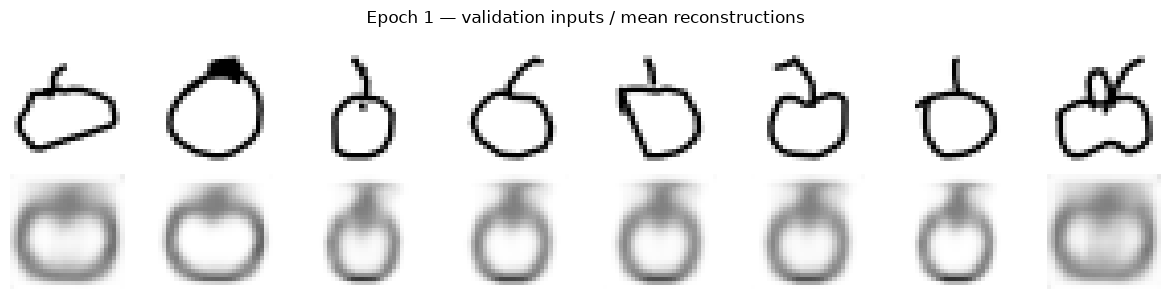

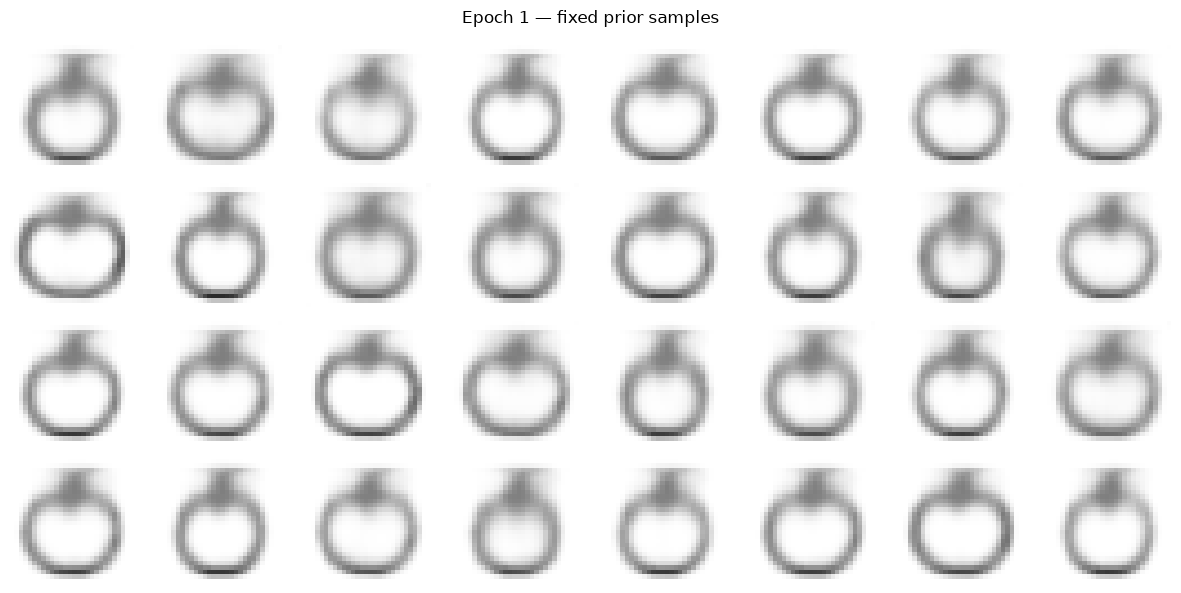

Epoch 1/5 | Train: 270.05 | Validation: 229.83 | Reconstruction: 225.16 | KL: 4.67 | Time: 1.9s


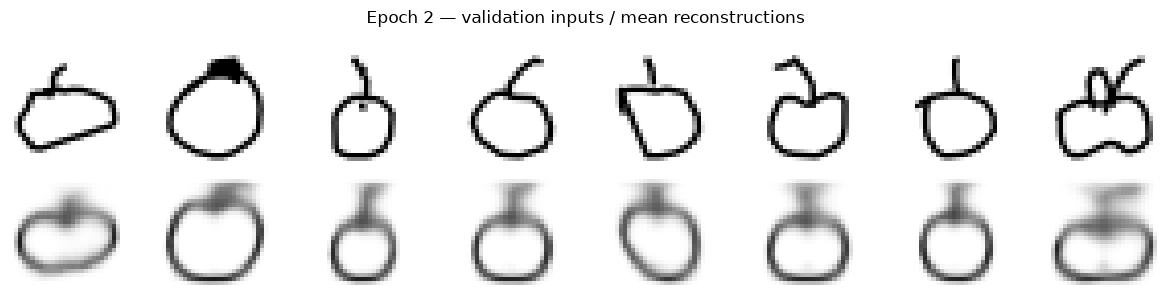

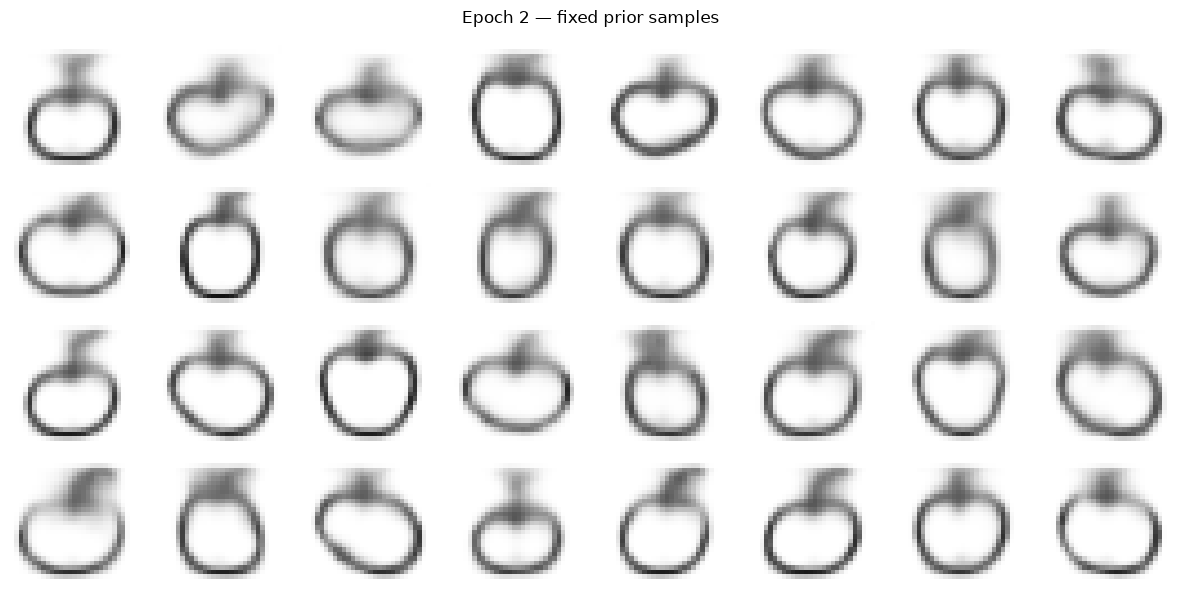

Epoch 2/5 | Train: 213.64 | Validation: 195.87 | Reconstruction: 184.54 | KL: 11.33 | Time: 1.7s


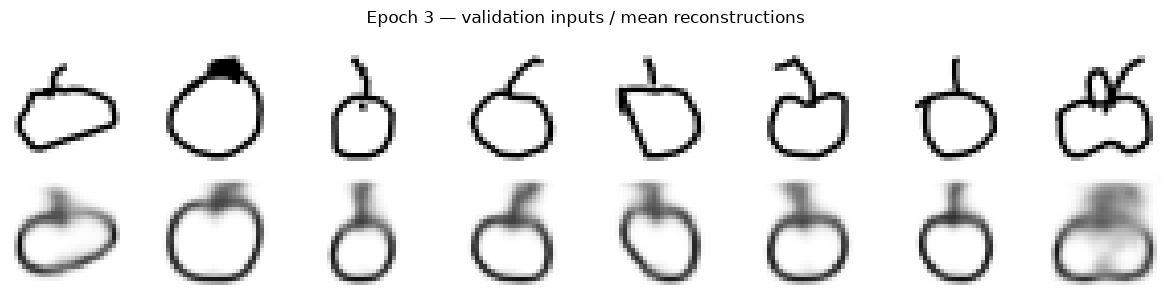

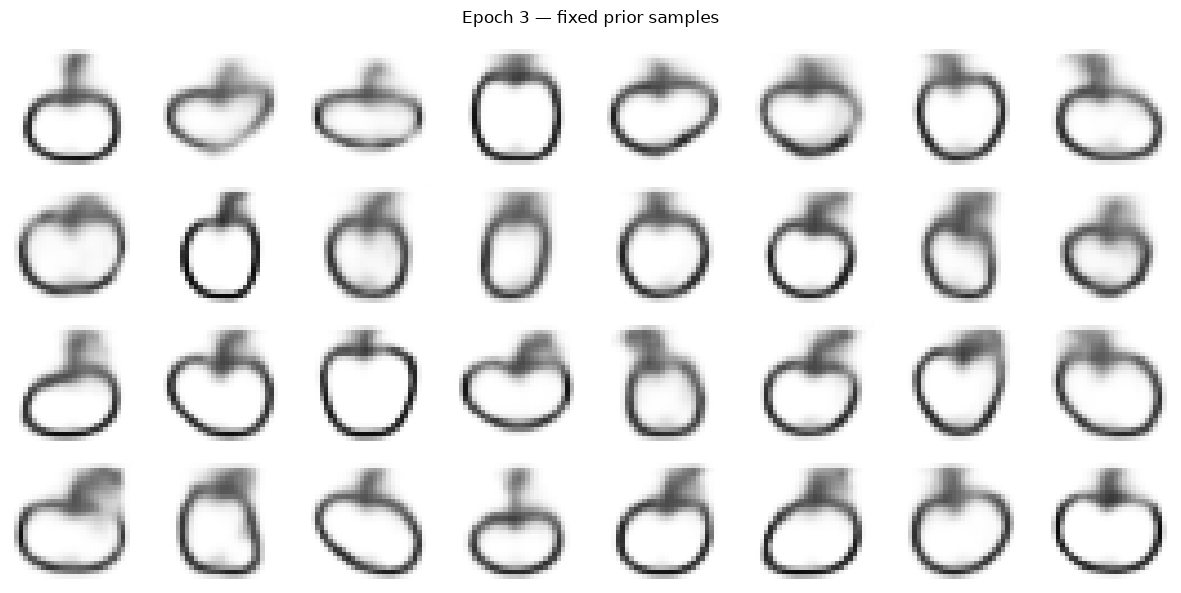

Epoch 3/5 | Train: 187.44 | Validation: 181.26 | Reconstruction: 167.29 | KL: 13.97 | Time: 1.7s


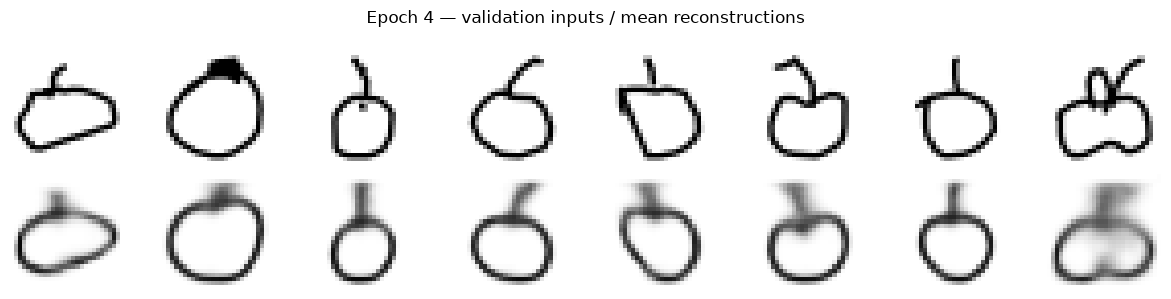

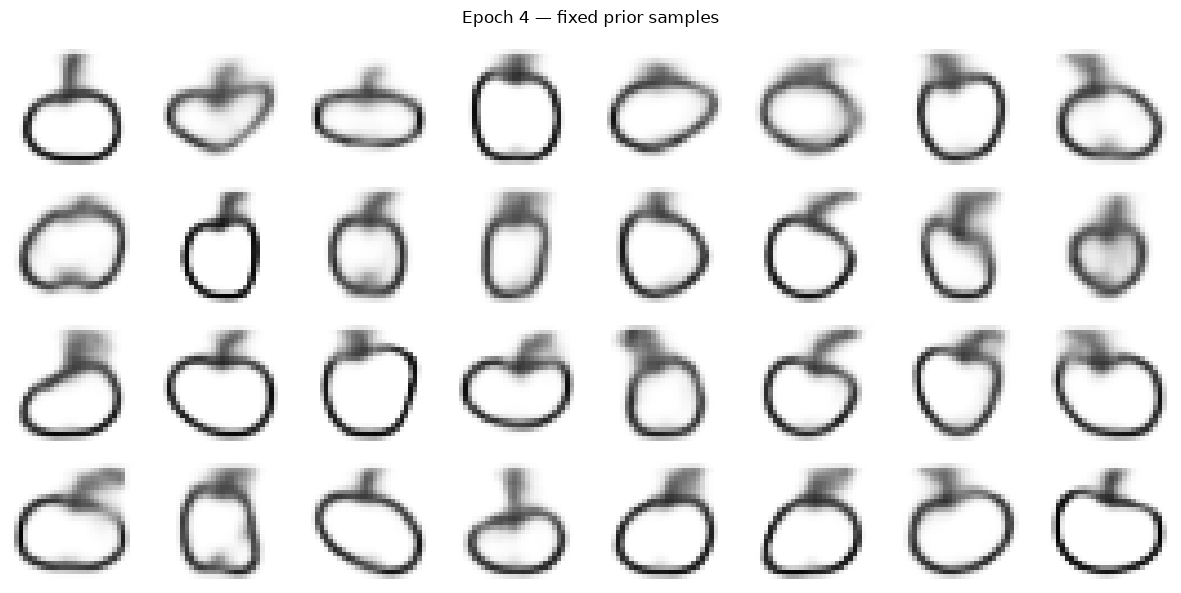

Epoch 4/5 | Train: 175.94 | Validation: 170.14 | Reconstruction: 154.16 | KL: 15.98 | Time: 1.7s


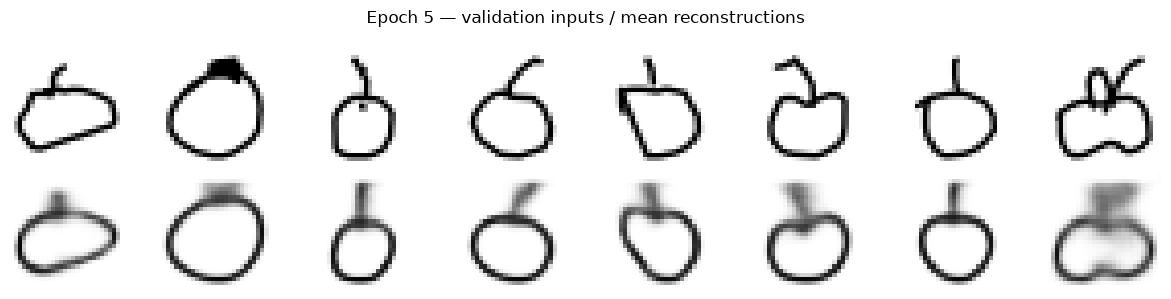

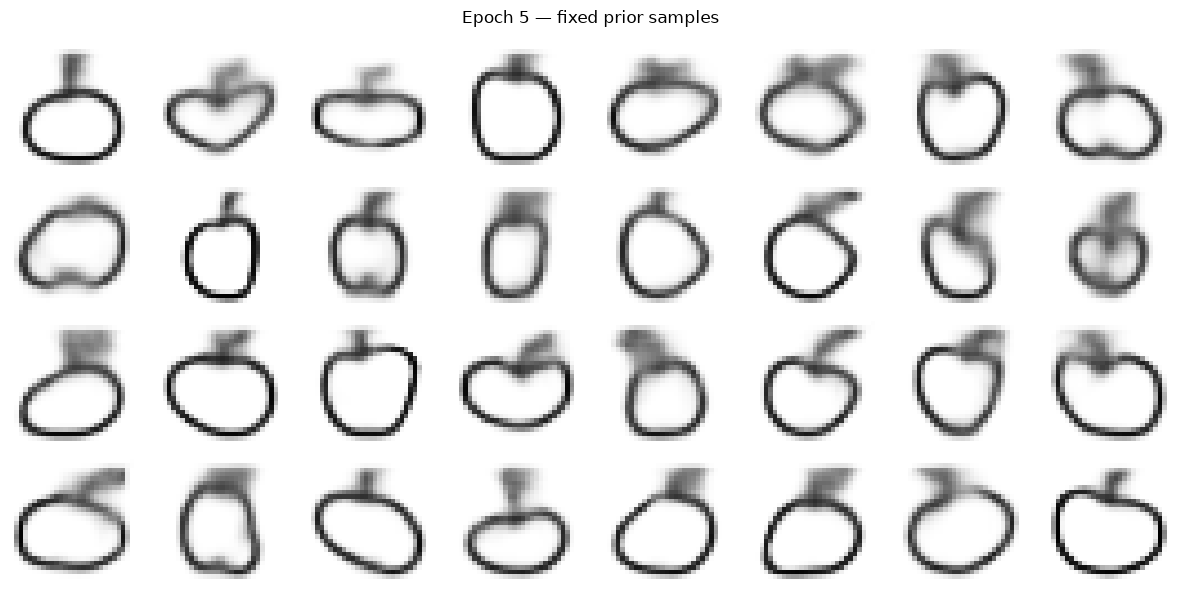

Epoch 5/5 | Train: 167.66 | Validation: 165.52 | Reconstruction: 147.66 | KL: 17.86 | Time: 1.7s


In [14]:
# Prevent accidental extra training if this cell is executed again.
if pilot_history or (pilot_run_dir / "checkpoints/latest.pt").exists():
    raise RuntimeError(
        "This run already has training progress. Resume from its checkpoint "
        "rather than rerunning this cell."
    )

for epoch in range(1, PILOT_EPOCHS + 1):
    started = perf_counter()

    train_metrics = train_vae_epoch(vae, train_loader, optimizer, device)
    validation_metrics = evaluate_vae(
        vae,
        validation_loader,
        device,
        seed=pilot_config["validation_noise_seed"]
    )

    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    pilot_history.append({
        "epoch": epoch,
        "seconds": perf_counter() - started,
        **{f"train_{key}": value for key, value in train_metrics.items()},
        **{
            f"validation_{key}": value
            for key, value in validation_metrics.items()
        }
    })

    improved = validation_metrics["total"] < best_validation
    best_validation = min(best_validation, validation_metrics["total"])

    checkpoint = {
        "epoch": epoch,
        "model": vae.state_dict(),
        "optimizer": optimizer.state_dict(),
        "config": pilot_config,
        "history": pilot_history,
        "best_validation": best_validation,
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "loader_rng": train_loader.generator.get_state()
    }
    if device.type == "mps":
        checkpoint["mps_rng"] = torch.mps.get_rng_state()
    elif device.type == "cuda":
        checkpoint["cuda_rng"] = torch.cuda.get_rng_state_all()

    latest_path = pilot_run_dir / "checkpoints/latest.pt"
    temporary_path = latest_path.with_suffix(".tmp")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(latest_path)

    if improved:
        shutil.copy2(latest_path, pilot_run_dir / "checkpoints/best.pt")

    pd.DataFrame(pilot_history).to_csv(pilot_run_dir / "reports/training_history.csv", index=False)

    vae.eval()
    with torch.no_grad():
        reconstruction_logits, _, _ = vae(
            fixed_validation, sample=False
        )
        reconstructions = reconstruction_logits.sigmoid().cpu()
        generations = vae.decode(fixed_latent).sigmoid().cpu()

    # Reconstructions and prior generations answer different questions.
    fig, axes = plt.subplots(2, 8, figsize=(12, 3))
    for index in range(8):
        axes[0, index].imshow(
            fixed_validation[index, 0].cpu(),
            cmap="gray_r", vmin=0, vmax=1
        )
        axes[1, index].imshow(
            reconstructions[index, 0],
            cmap="gray_r", vmin=0, vmax=1
        )
    for axis in axes.flat:
        axis.axis("off")
    fig.suptitle(
        f"Epoch {epoch} — validation inputs / mean reconstructions"
    )
    fig.tight_layout()
    fig.savefig(
        pilot_run_dir / f"figures/reconstructions_{epoch:02d}.png",
        dpi=120, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    fig, axes = plt.subplots(4, 8, figsize=(12, 6))
    for axis, generated in zip(axes.flat, generations):
        axis.imshow(
            generated[0],
            cmap="gray_r", vmin=0, vmax=1,
            interpolation="nearest"
        )
        axis.axis("off")
    fig.suptitle(f"Epoch {epoch} — fixed prior samples")
    fig.tight_layout()
    fig.savefig(
        pilot_run_dir / f"figures/generations_{epoch:02d}.png",
        dpi=120, bbox_inches="tight"
    )
    plt.savefig(f"figures/epoch_{epoch}_fixed_prior_samples")
    plt.show()
    plt.close(fig)

    print(
        f"Epoch {epoch}/{PILOT_EPOCHS} | "
        f"Train: {train_metrics['total']:.2f} | "
        f"Validation: {validation_metrics['total']:.2f} | "
        f"Reconstruction: {validation_metrics['reconstruction']:.2f} | "
        f"KL: {validation_metrics['kl']:.2f} | "
        f"Time: {pilot_history[-1]['seconds']:.1f}s",
        flush=True
    )

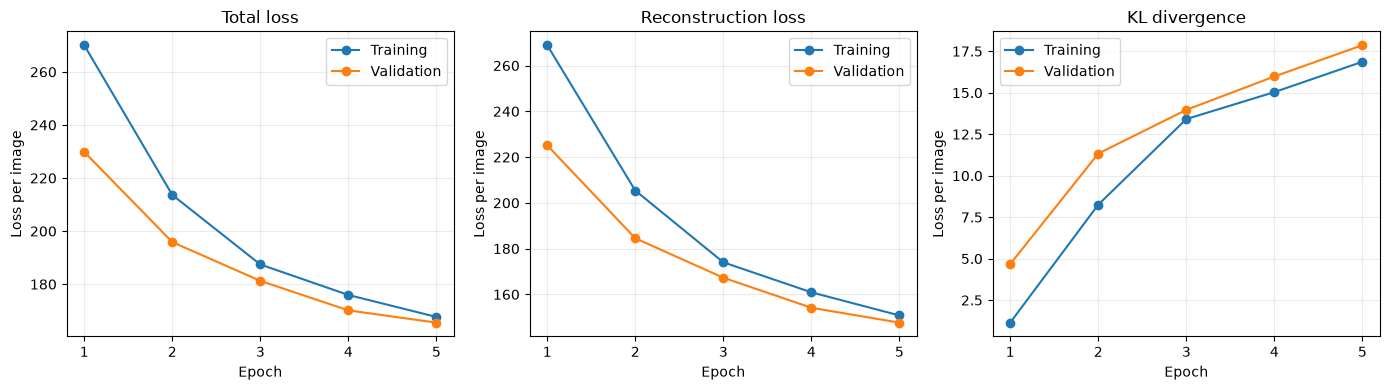

In [15]:
history_df = pd.DataFrame(pilot_history)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric, title in zip(
    axes,
    ["total", "reconstruction", "kl"],
    ["Total loss", "Reconstruction loss", "KL divergence"]
):
    for prefix, label in [
        ("train", "Training"),
        ("validation", "Validation")
    ]:
        ax.plot(
            history_df["epoch"],
            history_df[f"{prefix}_{metric}"],
            marker="o",
            label=label
        )

    ax.set(title=title, xlabel="Epoch", ylabel="Loss per image")
    ax.set_xticks(history_df["epoch"])
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
fig.savefig(
    pilot_run_dir / "figures" / "training_curves.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

## 8. Extended apple baseline: 20 total epochs

Continue from the five-epoch pilot using the same architecture, optimizer settings, and data splits. Preserve the pilot results in their original run directory and save continuation results separately.

Use the same fixed validation inputs and prior latent vectors to compare reconstruction quality and generated sketches across training stages. The test set remains unused during model development.

In [16]:
import copy

# Check that the completed pilot is still available in this kernel.
assert len(pilot_history) == 5, "Expected the completed five-epoch pilot."
assert pilot_history[-1]["epoch"] == 5

TOTAL_EPOCHS = 20

# Copy the trained model and Adam state so the pilot objects remain intact.
extended_vae = copy.deepcopy(vae)
extended_optimizer = torch.optim.Adam(extended_vae.parameters(), lr=LEARNING_RATE)
extended_optimizer.load_state_dict(copy.deepcopy(optimizer.state_dict()))

# Retain epochs 1–5 so the extended history covers the complete experiment.
extended_history = copy.deepcopy(pilot_history)
extended_best_validation = min(
    row["validation_total"] for row in extended_history
)

run_id = datetime.now(timezone.utc).strftime("apple_vae_extended_%Y%m%dT%H%M%S_%fZ")
extended_run_dir = PROJECT_ROOT / "runs" / run_id

for folder in ["figures", "reports", "checkpoints"]:
    (extended_run_dir / folder).mkdir(parents=True, exist_ok=False)

extended_config = {
    **pilot_config,
    "epochs": TOTAL_EPOCHS,
    "continued_from_run": pilot_run_dir.name,
    "continued_from_epoch": 5
}

(extended_run_dir / "reports" / "config.json").write_text(json.dumps(extended_config, indent=2), encoding="utf-8")

apple_manifest.to_csv(extended_run_dir / "reports" / "split_manifest.csv", index=False)

# Reuse the exact display inputs without drawing new random samples.
torch.save(
    {
        "validation_images": fixed_validation.cpu(),
        "prior_latent": fixed_latent.cpu()
    },
    extended_run_dir / "checkpoints" / "fixed_display_inputs.pt"
)

pd.DataFrame(extended_history).to_csv(extended_run_dir / "reports" / "training_history.csv", index=False)

print("Run directory:", extended_run_dir)
print("Completed epochs:", extended_history[-1]["epoch"])
print("Additional epochs:", TOTAL_EPOCHS - extended_history[-1]["epoch"])
print("Prepared trained model and optimizer; no new updates performed.")

Run directory: /Users/ashlabs/Projects/Masters in AI/github/sketch-generation-vae/runs/apple_vae_extended_20261109T191530_728371Z
Completed epochs: 5
Additional epochs: 15
Prepared trained model and optimizer; no new updates performed.


Epoch 6/20 | Train: 163.18 | Validation: 161.27 | Reconstruction: 142.94 | KL: 18.32 | Time: 1.8s
Epoch 7/20 | Train: 160.28 | Validation: 158.99 | Reconstruction: 140.10 | KL: 18.89 | Time: 1.7s
Epoch 8/20 | Train: 158.33 | Validation: 157.24 | Reconstruction: 138.34 | KL: 18.90 | Time: 1.7s
Epoch 9/20 | Train: 156.86 | Validation: 156.39 | Reconstruction: 136.80 | KL: 19.59 | Time: 1.7s
Epoch 10/20 | Train: 155.83 | Validation: 155.69 | Reconstruction: 136.54 | KL: 19.15 | Time: 1.7s


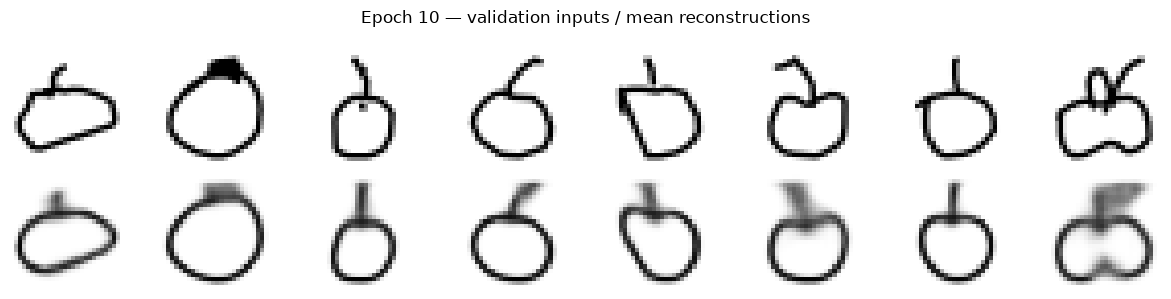

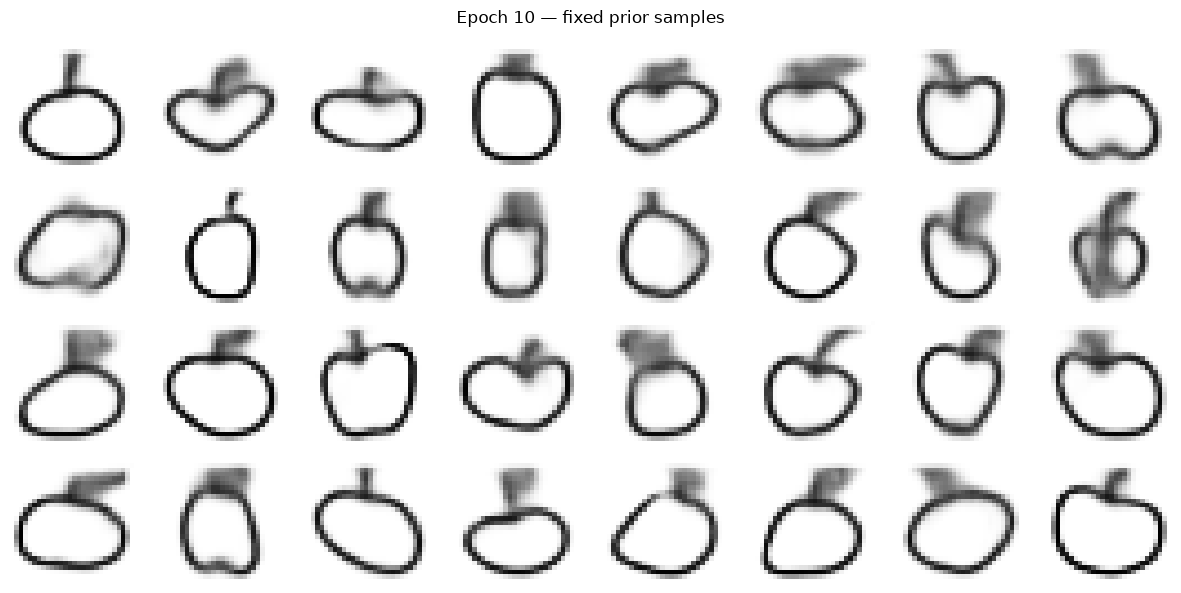

Epoch 11/20 | Train: 154.99 | Validation: 154.56 | Reconstruction: 134.96 | KL: 19.59 | Time: 1.7s
Epoch 12/20 | Train: 154.24 | Validation: 154.89 | Reconstruction: 135.49 | KL: 19.40 | Time: 1.7s
Epoch 13/20 | Train: 153.61 | Validation: 154.01 | Reconstruction: 134.51 | KL: 19.50 | Time: 1.7s
Epoch 14/20 | Train: 153.27 | Validation: 153.23 | Reconstruction: 133.68 | KL: 19.55 | Time: 1.7s
Epoch 15/20 | Train: 152.60 | Validation: 152.74 | Reconstruction: 132.84 | KL: 19.90 | Time: 1.7s


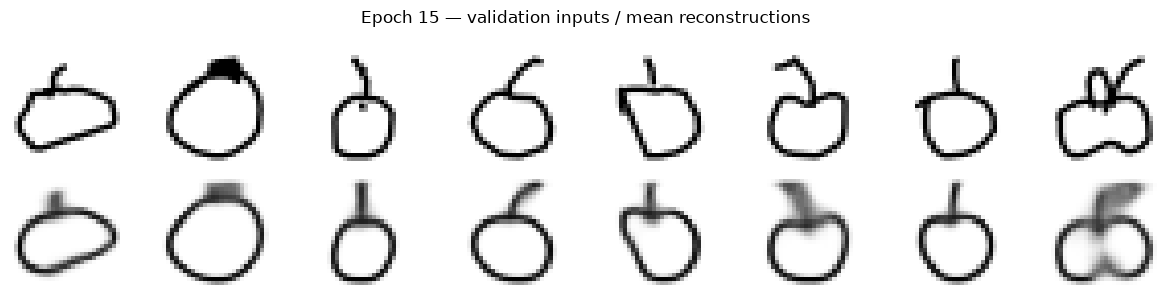

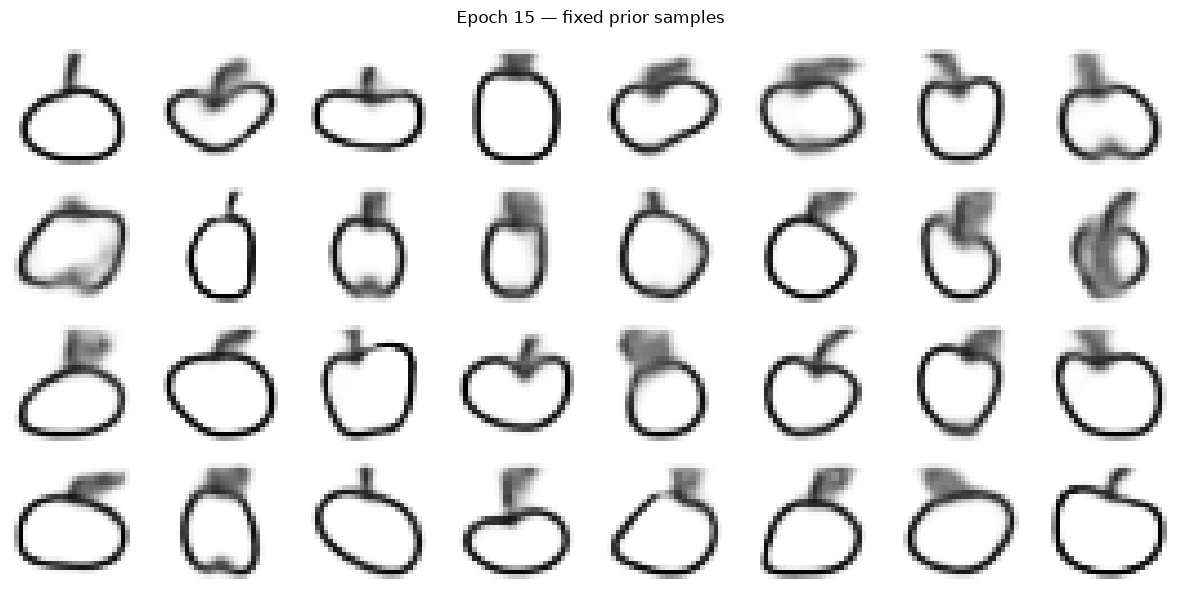

Epoch 16/20 | Train: 152.13 | Validation: 152.29 | Reconstruction: 131.83 | KL: 20.46 | Time: 1.7s
Epoch 17/20 | Train: 151.58 | Validation: 152.20 | Reconstruction: 131.90 | KL: 20.30 | Time: 1.7s
Epoch 18/20 | Train: 151.29 | Validation: 151.86 | Reconstruction: 131.12 | KL: 20.74 | Time: 1.7s
Epoch 19/20 | Train: 150.69 | Validation: 151.35 | Reconstruction: 130.44 | KL: 20.92 | Time: 1.7s
Epoch 20/20 | Train: 150.40 | Validation: 150.95 | Reconstruction: 130.00 | KL: 20.95 | Time: 1.7s


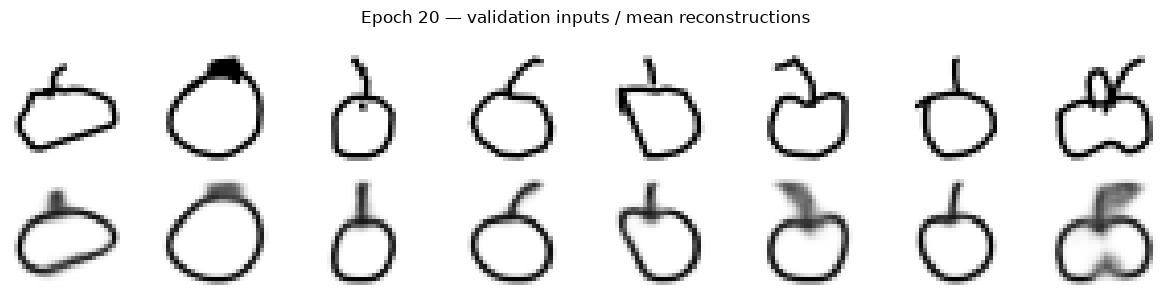

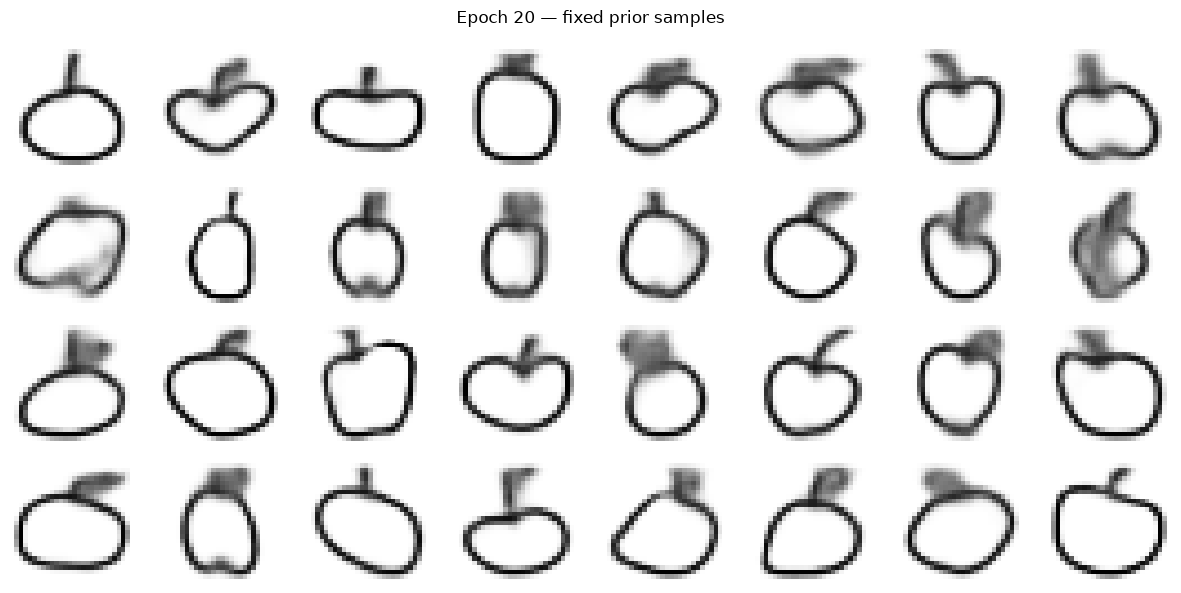

In [17]:
from time import perf_counter

latest_path = extended_run_dir / "checkpoints" / "latest.pt"
best_path = extended_run_dir / "checkpoints" / "best.pt"

# Prevent accidentally repeating updates by rerunning this cell.
if latest_path.exists() or extended_history[-1]["epoch"] != 5:
    raise RuntimeError(
        "Continuation has already started. Resume from a checkpoint "
        "instead of rerunning this cell."
    )

# Track the best checkpoint among the additional epochs.
best_continuation_validation = float("inf")

for epoch in range(6, TOTAL_EPOCHS + 1):
    started = perf_counter()

    train_metrics = train_vae_epoch(extended_vae, train_loader, extended_optimizer, device)
    validation_metrics = evaluate_vae(extended_vae, validation_loader, device)

    # Wait for GPU work before recording elapsed time.
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

    row = {
        "epoch": epoch,
        "seconds": perf_counter() - started,
        "train_total": train_metrics["total"],
        "train_reconstruction": train_metrics["reconstruction"],
        "train_kl": train_metrics["kl"],
        "validation_total": validation_metrics["total"],
        "validation_reconstruction": validation_metrics["reconstruction"],
        "validation_kl": validation_metrics["kl"]
    }
    extended_history.append(row)

    improved = row["validation_total"] < best_continuation_validation
    if improved:
        best_continuation_validation = row["validation_total"]

    # Save model, optimizer, history, and random states for later resumption.
    checkpoint = {
        "epoch": epoch,
        "model": extended_vae.state_dict(),
        "optimizer": extended_optimizer.state_dict(),
        "config": extended_config,
        "history": extended_history,
        "best_validation": best_continuation_validation,
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "loader_rng": train_loader.generator.get_state()
    }

    if device.type == "mps":
        checkpoint["mps_rng"] = torch.mps.get_rng_state()
    elif device.type == "cuda":
        checkpoint["cuda_rng"] = torch.cuda.get_rng_state_all()

    # Replace the checkpoint only after writing finishes successfully.
    temporary_path = latest_path.with_suffix(".pt.partial")
    torch.save(checkpoint, temporary_path)
    temporary_path.replace(latest_path)

    if improved:
        shutil.copy2(latest_path, best_path)

    pd.DataFrame(extended_history).to_csv(extended_run_dir / "reports" / "training_history.csv", index=False)

    print(
        f"Epoch {epoch}/{TOTAL_EPOCHS} | "
        f"Train: {row['train_total']:.2f} | "
        f"Validation: {row['validation_total']:.2f} | "
        f"Reconstruction: {row['validation_reconstruction']:.2f} | "
        f"KL: {row['validation_kl']:.2f} | "
        f"Time: {row['seconds']:.1f}s"
    )

    if epoch % 5 == 0:
        extended_vae.eval()
        with torch.no_grad():
            # Posterior means make reconstruction comparisons deterministic.
            reconstruction_logits, _, _ = extended_vae(fixed_validation, sample=False)
            reconstructions = reconstruction_logits.sigmoid().cpu()
            generations = extended_vae.decode(fixed_latent).sigmoid().cpu()

        fig, axes = plt.subplots(2, 8, figsize=(12, 3))
        for index in range(8):
            axes[0, index].imshow(
                fixed_validation[index, 0].cpu(),
                cmap="gray_r",
                vmin=0,
                vmax=1
            )
            axes[1, index].imshow(
                reconstructions[index, 0],
                cmap="gray_r", vmin=0, vmax=1
            )
            axes[0, index].axis("off")
            axes[1, index].axis("off")

        fig.suptitle(f"Epoch {epoch} — validation inputs / mean reconstructions")
        fig.tight_layout()
        fig.savefig(
            extended_run_dir / "figures" / f"reconstructions_{epoch:02d}.png",
            dpi=120,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

        fig, axes = plt.subplots(4, 8, figsize=(12, 6))
        for ax, image in zip(axes.flat, generations):
            ax.imshow(
                image[0],
                cmap="gray_r",
                vmin=0,
                vmax=1,
                interpolation="nearest"
            )
            ax.axis("off")

        fig.suptitle(f"Epoch {epoch} — fixed prior samples")
        fig.tight_layout()
        fig.savefig(
            extended_run_dir / "figures" / f"generations_{epoch:02d}.png",
            dpi=120,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

## 9. Multi-category dataset preparation

Extend the dataset to three Quick, Draw! categories: apple, mushroom, and umbrella. These categories provide distinct visual structures for
evaluating category-controlled generation.

Reuse the existing apple split. Audit the additional categories for blank images and exact duplicates before selecting 24,000 training, 3,000 validation, and 3,000 test images per category. Check exact duplicate overlap across categories and splits before training.

The conditional VAE will receive a category label alongside each image during training and alongside a sampled latent vector during generation.

In [18]:
CATEGORIES = ("apple", "mushroom", "umbrella")
CATEGORY_TO_ID = {
    category: index for index, category in enumerate(CATEGORIES)
}

category_images = {}
category_source_records = []

for category in CATEGORIES:
    url = (
        "https://storage.googleapis.com/"
        f"quickdraw_dataset/full/numpy_bitmap/{category}.npy"
    )
    path = PROJECT_ROOT / "data" / "raw" / f"{category}.npy"

    if not path.is_file():
        temporary_path = path.with_suffix(".npy.partial")

        # Publish the local file only after the download finishes.
        with urlopen(url, timeout=60) as response:
            expected_size = response.headers.get("Content-Length")
            with temporary_path.open("wb") as output:
                shutil.copyfileobj(response, output)

        if (
            expected_size is not None
            and temporary_path.stat().st_size != int(expected_size)
        ):
            raise RuntimeError(f"Incomplete download: {category}")

        temporary_path.replace(path)

    # Memory mapping avoids loading every category fully into RAM.
    images = np.load(path, mmap_mode="r", allow_pickle=False)
    assert images.ndim == 2 and images.shape[1] == 784
    assert images.dtype == np.uint8

    digest = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(chunk)

    category_images[category] = images
    category_source_records.append({
        "category": category,
        "category_id": CATEGORY_TO_ID[category],
        "url": url,
        "license": "CC BY 4.0",
        "sha256": digest.hexdigest(),
        "bytes": path.stat().st_size,
        "shape": list(images.shape),
        "dtype": str(images.dtype),
        "verified_at_utc": datetime.now(timezone.utc).isoformat()
    })

    print(
        f"{category}: {len(images):,} images | "
        f"{path.stat().st_size / 1024**2:.1f} MiB"
    )

# Confirm that the apple file matches the baseline's recorded source.
apple_source = next(
    record for record in category_source_records
    if record["category"] == "apple"
)
assert apple_source["sha256"] == pilot_config["source_sha256"]

source_report_path = PROJECT_ROOT / "reports" / "multicategory_sources.json"
source_report_path.write_text(
    json.dumps(category_source_records, indent=2),
    encoding="utf-8"
)

print("Category mapping:", CATEGORY_TO_ID)

apple: 144,722 images | 108.2 MiB
mushroom: 142,167 images | 106.3 MiB
umbrella: 124,084 images | 92.8 MiB
Category mapping: {'apple': 0, 'mushroom': 1, 'umbrella': 2}


In [19]:
# Process apple first so its existing split takes priority.
seen_hashes = set()
manifest_parts = []
audit_records = []

for category in CATEGORIES:
    images = category_images[category]
    unique_rows = []
    blank_count = 0
    duplicate_count = 0

    for source_index, pixels in enumerate(images):
        if not np.any(pixels):
            blank_count += 1
            continue

        pixel_hash = hashlib.sha256(pixels.tobytes()).hexdigest()

        # One shared set prevents exact duplicates across categories too.
        if pixel_hash in seen_hashes:
            duplicate_count += 1
            continue

        seen_hashes.add(pixel_hash)
        unique_rows.append({
            "source_index": source_index,
            "category": category,
            "pixel_sha256": pixel_hash
        })

    inventory = pd.DataFrame(unique_rows)

    if category == "apple":
        # Preserve the baseline's exact image selection and split assignments.
        selected = apple_manifest.copy()

        indexed_hashes = inventory.set_index("source_index")["pixel_sha256"]
        expected_hashes = selected["source_index"].map(indexed_hashes)
        assert expected_hashes.notna().all()
        assert expected_hashes.eq(selected["pixel_sha256"]).all()
    else:
        assert len(inventory) >= 30_000, (
            f"Not enough unique, nonblank images for {category}."
        )

        # Separate deterministic sampling for each additional category.
        rng = np.random.default_rng(SEED + CATEGORY_TO_ID[category])
        positions = rng.choice(
            len(inventory), size=30_000, replace=False
        )
        selected = inventory.iloc[positions].copy().reset_index(drop=True)

        selected["split"] = (
            ["train"] * 24_000
            + ["validation"] * 3_000
            + ["test"] * 3_000
        )

    selected["category_id"] = CATEGORY_TO_ID[category]
    manifest_parts.append(selected)

    audit_records.append({
        "category": category,
        "source_images": len(images),
        "blank_images_excluded": blank_count,
        "exact_duplicates_excluded": duplicate_count,
        "eligible_unique_images": len(inventory),
        "selected_images": len(selected)
    })

    print(
        f"{category}: {blank_count:,} blank | "
        f"{duplicate_count:,} duplicates | "
        f"{len(inventory):,} eligible"
    )

multicategory_manifest = pd.concat(manifest_parts, ignore_index=True)

# Verify uniqueness across the entire selected dataset, including splits.
assert multicategory_manifest["pixel_sha256"].is_unique
assert not multicategory_manifest.duplicated(
    ["category", "source_index"]
).any()

split_counts = pd.crosstab(
    multicategory_manifest["category"],
    multicategory_manifest["split"]
).reindex(index=CATEGORIES, columns=["train", "validation", "test"])

assert (split_counts["train"] == 24_000).all()
assert (split_counts["validation"] == 3_000).all()
assert (split_counts["test"] == 3_000).all()

multicategory_manifest.to_csv(
    PROJECT_ROOT / "data" / "processed" / "multicategory_split_manifest.csv",
    index=False
)

audit_report = {
    "seed": SEED,
    "category_mapping": CATEGORY_TO_ID,
    "apple_split_preserved": True,
    "duplicate_policy": (
        "First occurrence retained in category order: "
        "apple, mushroom, umbrella. All eligible source hashes are "
        "reserved before sampling the next category."
    ),
    "categories": audit_records
}

(PROJECT_ROOT / "reports" / "multicategory_data_audit.json").write_text(
    json.dumps(audit_report, indent=2),
    encoding="utf-8"
)

display(split_counts)
print("Selected images:", len(multicategory_manifest))
print("Exact pixel-hash overlap across selected splits: 0")

apple: 0 blank | 1 duplicates | 144,721 eligible
mushroom: 0 blank | 3 duplicates | 142,164 eligible
umbrella: 0 blank | 3 duplicates | 124,081 eligible


split,train,validation,test
category,,,
apple,24000,3000,3000
mushroom,24000,3000,3000
umbrella,24000,3000,3000


Selected images: 90000
Exact pixel-hash overlap across selected splits: 0


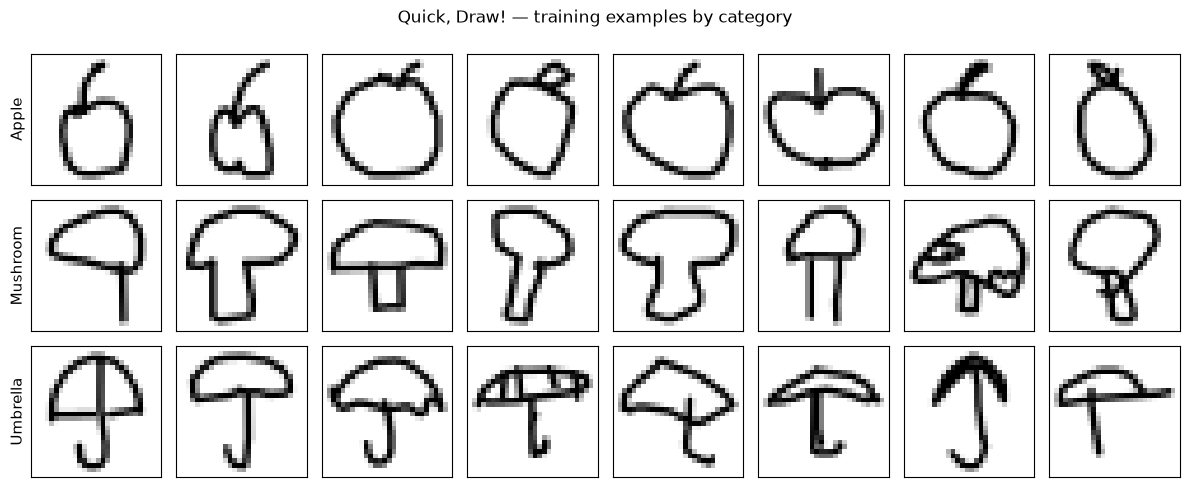

In [20]:
fig, axes = plt.subplots(3, 8, figsize=(12, 5))

for row, category in enumerate(CATEGORIES):
    # Preview training images only; keep the test set untouched.
    candidates = multicategory_manifest.loc[
        (multicategory_manifest["category"] == category)
        & (multicategory_manifest["split"] == "train")
    ]

    rng = np.random.default_rng(SEED + CATEGORY_TO_ID[category])
    positions = rng.choice(len(candidates), size=8, replace=False)
    selected = candidates.iloc[positions]

    for column, source_index in enumerate(selected["source_index"]):
        ax = axes[row, column]
        ax.imshow(
            category_images[category][int(source_index)].reshape(28, 28),
            cmap="gray_r",
            vmin=0,
            vmax=255,
            interpolation="nearest",
        )
        ax.set_xticks([])
        ax.set_yticks([])

        if column == 0:
            ax.set_ylabel(category.capitalize(), fontsize=11)

fig.suptitle("Quick, Draw! — training examples by category")
fig.tight_layout()
fig.savefig(
    PROJECT_ROOT / "figures" / "multicategory_training_examples.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()